# 01 — Wigner 𝔇 matrices and spin-weighted harmonics in JAX

This notebook introduces `spherical.jaxwigner`, a JAX implementation of the core of
`spherical.Wigner`, built to evaluate Wigner 𝔇 matrices and spin-weighted spherical
harmonics for **very large batches of rotations** on a GPU, with ℓ ≤ 8.

It covers:

1. Setup, and why 64-bit mode matters
2. Conventions: from quaternions to the phases $e^{i\alpha}, e^{i\beta}, e^{i\gamma}$
3. The $H$ "wedge" that the recursion computes
4. Wigner's $d$ and $\mathfrak{D}$ matrices, and how to index them
5. Spin-weighted spherical harmonics ${}_{s}Y_{\ell m}$
6. Validation against the numba implementation
7. Batching, `jit`, `vmap`, and compile-time behavior
8. Single precision

Later notebooks will cover computing rotated modes and waveforms directly, without
building 𝔇, and gradients.

## 1. Setup

JAX uses 32-bit floats unless told otherwise.  `spherical.jaxwigner` never changes that
setting itself, so enable 64-bit mode **before creating any arrays** when you want
results comparable to the numba implementation.

In [1]:
import time

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import quaternionic

import spherical
from spherical import jaxwigner as jw

print("JAX", jax.__version__, "devices:", jax.devices())

JAX 0.12.0.1 devices: [CpuDevice(id=0)]


## 2. Conventions: quaternions and Euler phases

Rotations are unit quaternions $R = [w, x, y, z]$, exactly as in `spherical` and
`quaternionic`.  The 𝔇 recursion does not need Euler angles themselves, only the three
phases

$$
z_\alpha = e^{i\alpha}, \qquad z_\beta = e^{i\beta}, \qquad z_\gamma = e^{i\gamma},
$$

which can be computed algebraically from the quaternion.  With $a = w^2 + z^2$ and
$b = x^2 + y^2$:

$$
z_\beta = \frac{(a - b) + 2i\sqrt{a}\sqrt{b}}{a + b}, \qquad
z_p = \frac{w + iz}{\sqrt a} = e^{i(\alpha+\gamma)/2}, \qquad
z_m = \frac{y - ix}{\sqrt b} = e^{i(\alpha-\gamma)/2},
$$

and $z_\alpha = z_p z_m$, $z_\gamma = z_p \bar z_m$.  This is what
`jw.euler_phases` returns.  Quaternions need not be normalized.

At the poles ($\beta = 0$ or $\pi$) only $\alpha + \gamma$ or $\alpha - \gamma$ is
defined; the other phase is set to 1, as in `quaternionic`, and the code avoids
producing NaN there.

In [2]:
α, β, γ = 0.4, 1.1, -0.7
R = quaternionic.array.from_euler_angles(α, β, γ)
zₐ, zᵦ, zᵧ = jw.euler_phases(R.ndarray)

print("from the quaternion:", complex(zₐ), complex(zᵦ), complex(zᵧ))
print("from the angles:    ", np.exp(1j * α), np.exp(1j * β), np.exp(1j * γ))

from the quaternion: (0.921060994002885+0.3894183423086506j) (0.4535961214255772+0.8912073600614355j) (0.7648421872844883-0.644217687237691j)
from the angles:     (0.9210609940028851+0.3894183423086505j) (0.4535961214255773+0.8912073600614354j) (0.7648421872844885-0.644217687237691j)


## 3. The $H$ wedge

Rather than computing $d^\ell_{m',m}(\beta)$ directly, the recursion of Gumerov &
Duraiswami ([arXiv:1403.7698](https://arxiv.org/abs/1403.7698)) computes a closely
related real quantity,

$$
d^\ell_{m',m} = \epsilon_{m'}\,\epsilon_{-m}\,H^\ell_{m',m}, \qquad
\epsilon_k = \begin{cases} 1 & k \le 0 \\ (-1)^k & k > 0 \end{cases}
$$

whose symmetries $H^\ell_{m',m} = H^\ell_{m,m'} = H^\ell_{-m',-m}$ mean only the
**wedge** $m \ge |m'|$ needs to be computed — roughly a quarter of the matrix.

`jw.H_wedge` returns the wedge as a dict of **rows**: key $(\ell, m')$ holds an array of
$H^\ell_{m',m}$ for $m = |m'|, \ldots, \ell$.  Each row is computed as one vector
operation, which keeps compile times short.  `jw.H_element` looks up any element,
using the symmetries.

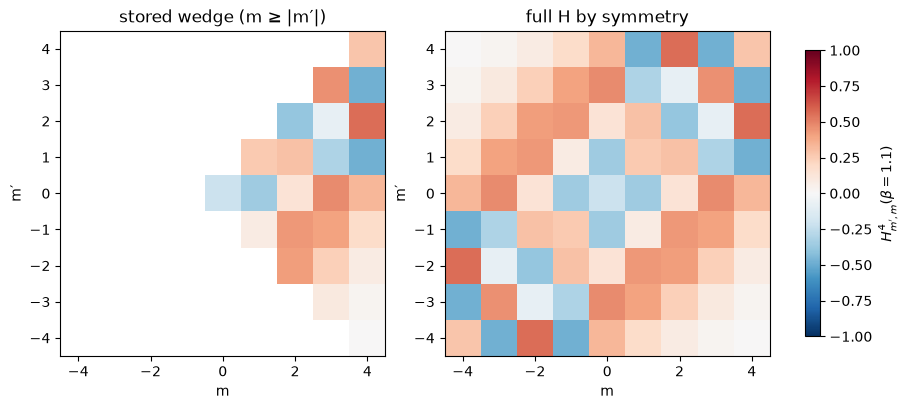

In [3]:
ell = 4
H = jw.H_wedge(jnp.exp(1j * 1.1), ell)

# Show which (m′, m) elements are stored for ℓ = 4
stored = np.full((2 * ell + 1, 2 * ell + 1), np.nan)
for mp in range(-ell, ell + 1):
    for m in range(abs(mp), ell + 1):
        stored[mp + ell, m + ell] = H[ell, mp][m - abs(mp)]
full = np.array([[jw.H_element(H, ell, mp, m) for m in range(-ell, ell + 1)]
                 for mp in range(-ell, ell + 1)])

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for ax, data, title in zip(axes, (stored, full), ("stored wedge (m ≥ |m′|)", "full H by symmetry")):
    im = ax.imshow(data, cmap="RdBu_r", vmin=-1, vmax=1, origin="lower",
                   extent=(-ell - 0.5, ell + 0.5, -ell - 0.5, ell + 0.5))
    ax.set(title=title, xlabel="m", ylabel="m′")
fig.colorbar(im, ax=axes, shrink=0.8, label=r"$H^4_{m',m}(\beta=1.1)$")
plt.show()

## 4. The $d$ and $\mathfrak{D}$ matrices

`jw.wigner_d(expiβ, ell_max, ell_min=0)` and `jw.wigner_D(R, ell_max, ell_min=0)` return
**flat arrays in exactly the same layout as `spherical`**:

```
[X(ℓ, m′, m) for ℓ in range(ell_min, ell_max+1)
             for m′ in range(-ℓ, ℓ+1)
             for m in range(-ℓ, ℓ+1)]
```

so `spherical.WignerDindex(ℓ, m′, m, ell_min)` gives the position of an element.  Any
leading batch dimensions of the input are kept.  The full 𝔇 is

$$
\mathfrak{D}^\ell_{m',m}(R) = d^\ell_{m',m}(\beta)\; z_\alpha^{m'}\, z_\gamma^{m}.
$$

`ell_max` and `ell_min` are **static** arguments: each distinct value compiles a new
function, the first time it is used.

d shape: (200, 35)


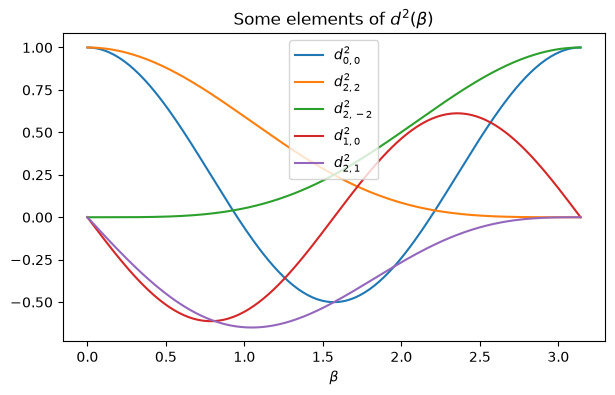

In [4]:
β = np.linspace(0, np.pi, 200)
d = jw.wigner_d(np.exp(1j * β), 2)  # shape (200, WignerDsize(0, 2)) = (200, 35)
print("d shape:", d.shape)

fig, ax = plt.subplots(figsize=(7, 4))
for mp, m in [(0, 0), (2, 2), (2, -2), (1, 0), (2, 1)]:
    ax.plot(β, d[:, spherical.WignerDindex(2, mp, m)], label=f"$d^2_{{{mp},{m}}}$")
ax.set(xlabel=r"$\beta$", title=r"Some elements of $d^2(\beta)$")
ax.legend()
plt.show()

For matrix operations it is convenient to reshape one ℓ block into a
$(2\ell+1)\times(2\ell+1)$ matrix.  For example, each block is unitary, and the blocks
compose like the rotations: $\mathfrak{D}^\ell(R_1 R_2) = \mathfrak{D}^\ell(R_1)\,\mathfrak{D}^\ell(R_2)$.

In [5]:
def D_block(D, ell, ell_min=0):
    i1 = spherical.WignerDindex(ell, -ell, -ell, ell_min)
    i2 = spherical.WignerDindex(ell, ell, ell, ell_min) + 1
    return D[..., i1:i2].reshape(D.shape[:-1] + (2 * ell + 1, 2 * ell + 1))

rng = np.random.default_rng(0)
R1, R2 = (quaternionic.array(rng.normal(size=4)).normalized for _ in range(2))
D1, D2, D12 = (jw.wigner_D(q.ndarray, 8) for q in (R1, R2, R1 * R2))

for ell in (2, 8):
    Dˡ = D_block(D1, ell)
    unitarity = jnp.max(jnp.abs(Dˡ @ Dˡ.conj().T - jnp.eye(2 * ell + 1)))
    composition = jnp.max(jnp.abs(D_block(D1, ell) @ D_block(D2, ell) - D_block(D12, ell)))
    print(f"ℓ={ell}: max |𝔇𝔇† − I| = {unitarity:.1e},  max |𝔇(R₁)𝔇(R₂) − 𝔇(R₁R₂)| = {composition:.1e}")

ℓ=2: max |𝔇𝔇† − I| = 8.9e-16,  max |𝔇(R₁)𝔇(R₂) − 𝔇(R₁R₂)| = 7.4e-16


ℓ=8: max |𝔇𝔇† − I| = 2.2e-15,  max |𝔇(R₁)𝔇(R₂) − 𝔇(R₁R₂)| = 1.8e-15


## 5. Spin-weighted spherical harmonics

$$
{}_{s}Y_{\ell m}(R) = (-1)^s \sqrt{\frac{2\ell+1}{4\pi}}\;\mathfrak{D}^\ell_{m,-s}(R),
$$

so `jw.sYlm(s, R, ell_max)` needs only one column of 𝔇 per ℓ, and computes only that.
It returns modes in the layout `[Y(ℓ, m) for ℓ in range(ell_min, ell_max+1) for m in
range(-ℓ, ℓ+1)]`, indexed by `spherical.Yindex(ℓ, m, ell_min)`; entries with ℓ < |s| are
zero.

To evaluate at a point $(\theta, \phi)$ on the sphere, use the rotor
`quaternionic.array.from_spherical_coordinates(θ, ϕ)`.  Here are the real parts of the
two dominant gravitational-wave harmonics, ${}_{-2}Y_{22}$ and ${}_{-2}Y_{21}$, over the sphere:

Y shape: (91, 181, 5)


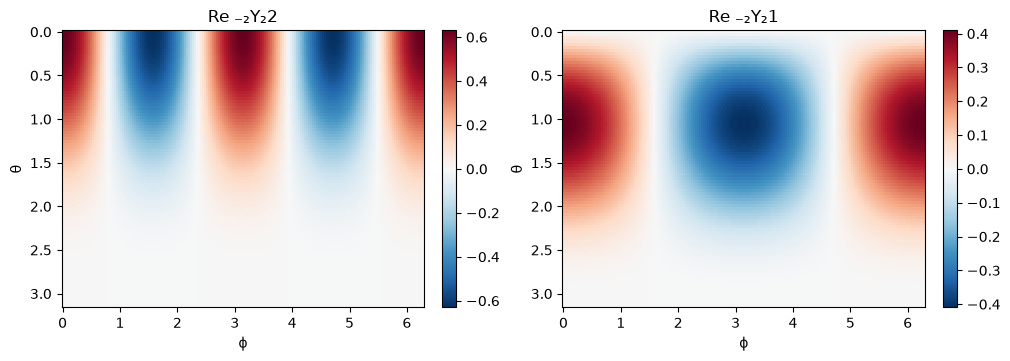

In [6]:
θ = np.linspace(0, np.pi, 91)
ϕ = np.linspace(0, 2 * np.pi, 181)
Θ, Φ = np.meshgrid(θ, ϕ, indexing="ij")
R_grid = quaternionic.array.from_spherical_coordinates(Θ, Φ).ndarray  # shape (91, 181, 4)

Y = jw.sYlm(-2, R_grid, 2, ell_min=2)  # shape (91, 181, 5): m = -2, ..., 2
print("Y shape:", Y.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for ax, m in zip(axes, (2, 1)):
    im = ax.pcolormesh(Φ, Θ, Y[..., spherical.Yindex(2, m, 2)].real, cmap="RdBu_r", shading="auto")
    ax.set(title=f"Re ₋₂Y₂{m}", xlabel="ϕ", ylabel="θ")
    ax.invert_yaxis()
    fig.colorbar(im, ax=ax)
plt.show()

## 6. Validation against the numba implementation

The numba `spherical.Wigner` class is the reference.  The test suite
(`tests/test_jaxwigner.py`) compares every output for ℓ ≤ 8, including rotors at and
near the poles, and also checks identities that do not depend on any reference:
unitarity, composition, inverses, invariance under $R \to -R$ and rescaling,
orthonormality of ${}_{-2}Y_{\ell m}$, and closed forms for ℓ = 1.

Here is the maximum difference for each ℓ over a batch of random rotors.  It stays
within a few units of machine precision ($2.2\times10^{-16}$):

In [7]:
R = quaternionic.array(rng.normal(size=(1000, 4))).normalized
ell_max = 8
D_jax = np.asarray(jw.wigner_D(R.ndarray, ell_max))
D_ref = spherical.Wigner(ell_max).D(R)

for ell in range(ell_max + 1):
    error = np.max(np.abs(D_block(D_jax, ell) - D_block(D_ref, ell)))
    print(f"ℓ={ell}: max |𝔇_jax − 𝔇_numba| = {error:.1e}")

ℓ=0: max |𝔇_jax − 𝔇_numba| = 0.0e+00
ℓ=1: max |𝔇_jax − 𝔇_numba| = 8.7e-16
ℓ=2: max |𝔇_jax − 𝔇_numba| = 1.3e-15
ℓ=3: max |𝔇_jax − 𝔇_numba| = 1.3e-15
ℓ=4: max |𝔇_jax − 𝔇_numba| = 1.9e-15
ℓ=5: max |𝔇_jax − 𝔇_numba| = 2.3e-15
ℓ=6: max |𝔇_jax − 𝔇_numba| = 2.8e-15
ℓ=7: max |𝔇_jax − 𝔇_numba| = 3.0e-15
ℓ=8: max |𝔇_jax − 𝔇_numba| = 4.1e-15


## 7. Batching, `jit`, `vmap`, and compile time

All functions accept quaternions with any leading batch shape `(..., 4)`.  Internally,
every operation is elementwise across the batch, so XLA can fuse the recursion into a
few kernels in which each GPU thread handles one rotor.  `vmap` and nesting inside your
own `jit`-compiled functions work as usual.

The first call for a given `ell_max` (and input shape) compiles; later calls are fast.
Changing the **batch size** also triggers a recompile, so in a real pipeline keep shapes
fixed (pad if necessary).

The timings below are on this machine's **CPU**.  They are only an illustration: GPU
benchmarks are a separate step.

In [8]:
def timed(f, *args, repeat=5):
    f(*args).block_until_ready()  # make sure compilation is excluded
    t = time.perf_counter()
    for _ in range(repeat):
        f(*args).block_until_ready()
    return (time.perf_counter() - t) / repeat

ell_max = 8
for N in (2_000, 20_000, 200_000):
    R = quaternionic.array(rng.normal(size=(N, 4))).normalized
    t0 = time.perf_counter()
    jw.wigner_D(R.ndarray, ell_max).block_until_ready()
    first = time.perf_counter() - t0
    t_jax = timed(lambda q: jw.wigner_D(q, ell_max), R.ndarray)
    wigner = spherical.Wigner(ell_max)
    t = time.perf_counter(); wigner.D(R); t_numba = time.perf_counter() - t
    print(f"N={N:>7}: first call {first:5.2f} s;  JAX {t_jax*1e3:7.1f} ms;  numba {t_numba*1e3:7.1f} ms")

N=   2000: first call  1.66 s;  JAX     3.7 ms;  numba    20.6 ms


N=  20000: first call  2.16 s;  JAX    41.9 ms;  numba   248.2 ms


N= 200000: first call  4.28 s;  JAX  1061.5 ms;  numba  2700.8 ms


In [9]:
# vmap over a single-rotor function gives the same result as passing the batch directly
R = quaternionic.array(rng.normal(size=(100, 4))).normalized.ndarray
per_rotor = jax.vmap(lambda q: jw.sYlm(-2, q, 8))(R)
batched = jw.sYlm(-2, R, 8)
print("max difference, vmap vs batch:", float(jnp.max(jnp.abs(per_rotor - batched))))

max difference, vmap vs batch: 0.0


## 8. Single precision

Consumer GPUs are much faster in float32 than float64.  The functions follow the
precision of their input, so passing `float32` quaternions gives `complex64` results.
For ℓ ≤ 8 the error is around $10^{-6}$:

In [10]:
R = quaternionic.array(rng.normal(size=(10_000, 4))).normalized.ndarray
D64 = jw.wigner_D(R, 8)
D32 = jw.wigner_D(R.astype(np.float32), 8)
print("dtype:", D32.dtype)
for ell in (0, 2, 4, 8):
    error = jnp.max(jnp.abs(D_block(D32, ell) - D_block(D64, ell)))
    print(f"ℓ={ell}: max |𝔇_float32 − 𝔇_float64| = {error:.1e}")

dtype: complex64
ℓ=0: max |𝔇_float32 − 𝔇_float64| = 0.0e+00


ℓ=2: max |𝔇_float32 − 𝔇_float64| = 8.7e-07
ℓ=4: max |𝔇_float32 − 𝔇_float64| = 1.1e-06


ℓ=8: max |𝔇_float32 − 𝔇_float64| = 2.1e-06


## Summary

| Function | Input | Output |
|---|---|---|
| `jw.euler_phases(R)` | `(..., 4)` quaternions | $(z_\alpha, z_\beta, z_\gamma)$, each `(...)` |
| `jw.H_wedge(expiβ, ell_max)` | `(...)` complex | dict of rows `(ℓ, m′) → (..., ℓ−|m′|+1)` |
| `jw.wigner_d(expiβ, ell_max, ell_min=0)` | `(...)` complex | `(..., WignerDsize)` real |
| `jw.wigner_D(R, ell_max, ell_min=0)` | `(..., 4)` | `(..., WignerDsize)` complex |
| `jw.sYlm(s, R, ell_max, ell_min=0)` | `(..., 4)` | `(..., Ysize)` complex |

Points to remember:

- Enable `jax_enable_x64` for float64 results.
- `s`, `ell_max` and `ell_min` are static: each new value compiles a new function, as does
  each new input shape.
- Building the full 𝔇 is often unnecessary.  The next stage adds functions that rotate
  modes and evaluate waveforms directly from the $H$ wedge.